In [34]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

# print mixomics version
packageVersion("mixOmics")

[1] ‘6.26.0’

In [35]:
DATA_DIR <- "/home/mariya/Data/pallas"
TRAIN_DATA_DIR <- file.path(DATA_DIR, "mlomix_datasets/train-bimodal-reduced")
METH_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")
OUTPUT_DIR <- file.path(DATA_DIR, "mixOmics")

In [36]:
source("helpers.R")
train_data <- data(GEX_TRAIN_FILE, METH_TRAIN_FILE, LABELS_TRAIN_FILE)

Samples: 868 
GEX features: 199 
DNAm features: 6582 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, FUS::ERG AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, PICALM::MLLT10 AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5 P80R B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [37]:
X_gex_train <- train_data$X_gex
X_dnam_train <- train_data$X_dnam
Y_train     <- train_data$Y

head(X_gex_train)
head(X_dnam_train)
head(Y_train)

,ENSG00000079102,ENSG00000175505,ENSG00000185917,ENSG00000145113,ENSG00000102098,ENSG00000248329,ENSG00000164853,ENSG00000173825,ENSG00000073792,ENSG00000067177,⋯,ENSG00000164741,ENSG00000167528,ENSG00000114757,ENSG00000189325,ENSG00000132780,ENSG00000106004,ENSG00000175591,ENSG00000188269,ENSG00000142599,ENSG00000106665
ALL_1000,-1.596042,0.9493361,3.579807,-0.1403364,5.470482,13.046647,-1.596042,3.1679255,4.438548,1.2341500,⋯,-0.5086183,2.402686,-1.44748104,-1.596042,5.759100,3.593846,-0.3247489,-1.596042,7.283158,7.320186
ALL_1003,-1.596042,0.1570900,4.639638,-0.7255331,3.311799,-1.596042,-1.596042,0.8211017,3.970013,-1.2468383,⋯,-1.1032802,1.938077,-1.59604226,8.005105,7.045988,4.519395,-1.5960423,-1.596042,5.872816,8.132837
ALL_1005,-1.596042,-0.3729515,3.844026,2.0149281,5.150147,-1.596042,-1.596042,0.8482443,1.767218,-1.2297735,⋯,-1.4029350,3.076956,-1.59604226,-1.596042,7.105609,-1.596042,-1.5313228,-1.596042,4.940420,5.759756
ALL_1019,-1.596042,6.0413562,4.032419,-0.2970125,5.670480,-1.596042,-1.596042,4.0550008,2.290460,-1.2768282,⋯,-0.9616693,2.489532,-0.04867884,7.690148,6.713472,-1.596042,3.7400111,8.262904,5.732026,8.926576
ALL_1031,-1.596042,0.2815531,4.268223,2.4014250,5.320415,-1.596042,-1.596042,2.0749346,2.902432,-0.8894692,⋯,-1.4989847,2.631650,-1.59604226,-1.596042,6.975484,-1.596042,-1.5960423,-1.596042,5.378111,8.659184
ALL_1039,-1.596042,3.7105731,3.563106,5.9114389,4.290925,-1.596042,-1.596042,2.3230306,4.204582,-1.2207872,⋯,1.7752557,3.096701,-1.59604226,-1.280366,6.222201,-0.964650,4.8774092,-1.596042,6.025827,9.276772


,cg17259886,cg13293524,cg16288865,cg12923179,cg11622162,cg07232063,cg03763508,cg18638389,cg02707071,cg08166720,⋯,cg19557110,cg08911692,cg05807885,cg00527174,cg08473752,cg08870143,cg06814191,cg06710207,cg08523727,cg06671690
ALL_1000,0.9628,0.9734,0.2669,0.9124,0.0519,0.8871,0.9589,0.9350,0.9530,0.9419,⋯,0.9679,0.9551,0.0817,0.0413,0.9560,0.9348,0.9375,0.9353,0.1773,0.3090
ALL_1003,0.9543,0.9784,0.9405,0.9111,0.0512,0.9138,0.9501,0.9287,0.9587,0.9059,⋯,0.9557,0.9493,0.0343,0.1358,0.9543,0.9377,0.9402,0.9389,0.8985,0.0131
ALL_1005,0.9567,0.9688,0.9195,0.9326,0.0571,0.9326,0.8014,0.9232,0.9447,0.9334,⋯,0.9486,0.9413,0.5024,0.0513,0.9357,0.9436,0.9134,0.9285,0.5752,0.2365
ALL_1019,0.9406,0.9741,0.9442,0.9032,0.0394,0.6195,0.9358,0.9481,0.9608,0.4691,⋯,0.9561,0.9526,0.0308,0.1097,0.9293,0.9478,0.9392,0.8979,0.9337,0.0127
ALL_1031,0.9483,0.9751,0.9297,0.9276,0.0503,0.8530,0.9576,0.9438,0.9563,0.9559,⋯,0.9623,0.9613,0.3448,0.0494,0.9553,0.6602,0.9439,0.9418,0.9432,0.0560
ALL_1039,0.9539,0.9782,0.9439,0.9222,0.0484,0.9325,0.9549,0.9351,0.9427,0.9470,⋯,0.9541,0.9524,0.1041,0.0670,0.9273,0.6549,0.8594,0.9298,0.9235,0.0121


[1] B-ALL, DUX4-r         B-ALL, PAX5alt        B-ALL, MEF2D-r       
[4] B-ALL, ZNF384-r       B-ALL, BCR::ABL1-like B-ALL, BCR::ABL1     
28 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

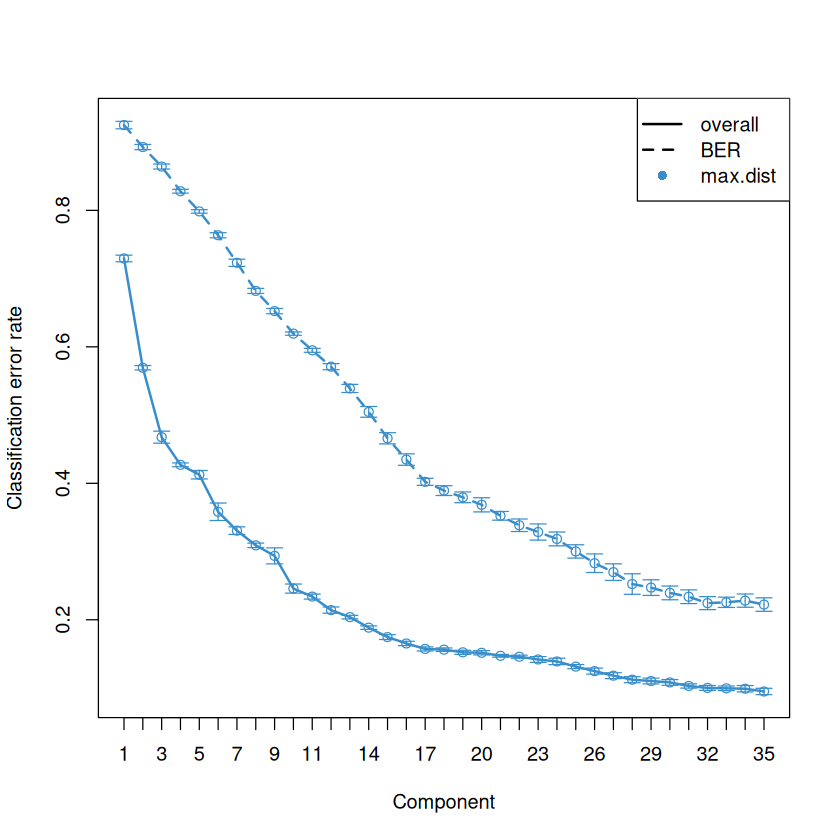

In [38]:
FOLDS     <- 3
NREPEAT   <- 10
MAX_NCOMP <- 35
KEEP_X    <- 30 # min(ncol(X_gex_train), 200)  # smaller of number of features or 200
DIST      <- "max.dist"
bpparam <- MulticoreParam(workers = parallel::detectCores() - 1)

gex_prelim <- splsda(X_gex_train, Y_train,
                     ncomp = MAX_NCOMP,
                     keepX = rep(KEEP_X, MAX_NCOMP))
gex_perf   <- perf(gex_prelim,
                   validation  = "Mfold",
                   folds       = FOLDS,
                   nrepeat     = NREPEAT,
                   dist        = DIST,
                   BPPARAM     = bpparam,
                   progressBar = FALSE)

# Plot BER across all components to see the curve shape
plot(gex_perf, criterion = "BER")
saveRDS(gex_perf,    file.path(OUTPUT_DIR, "gex_perf.rds"))

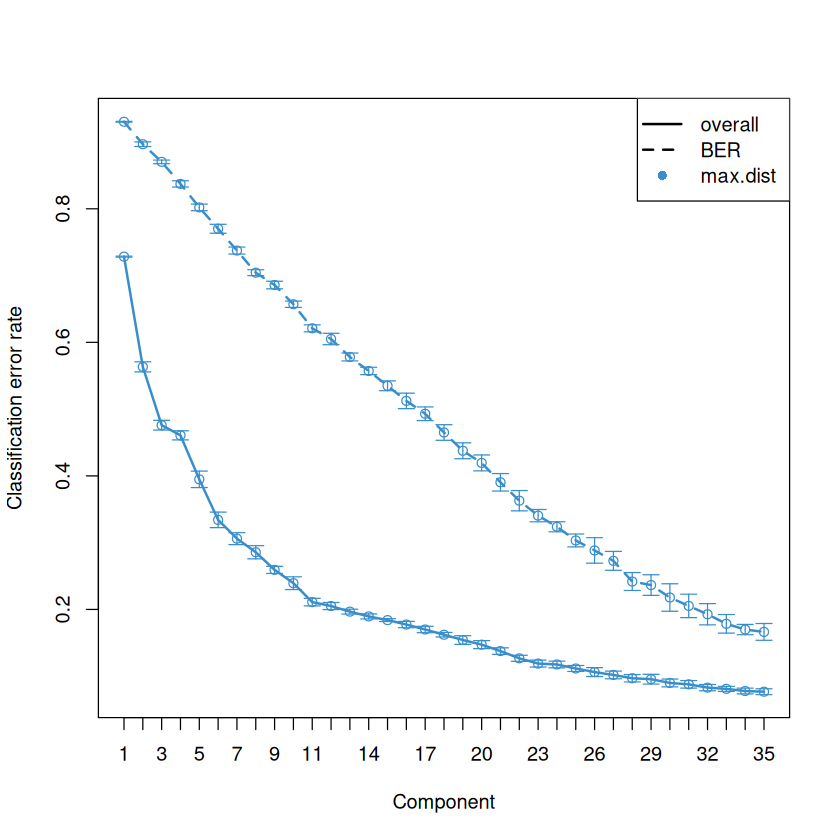

In [39]:
# ============================================================
# DNAm
# ============================================================
dnam_prelim <- splsda(X_dnam_train, Y_train,
                      ncomp = MAX_NCOMP,
                      keepX = rep(KEEP_X, MAX_NCOMP))
dnam_perf   <- perf(dnam_prelim,
                    validation  = "Mfold",
                    folds       = FOLDS,
                    nrepeat     = NREPEAT,
                    dist        = DIST,
                    BPPARAM     = bpparam,
                    progressBar = FALSE)
plot(dnam_perf, criterion = "BER")
saveRDS(dnam_perf,   file.path(OUTPUT_DIR, "dnam_perf.rds"))

Design matrix has changed to include Y; each block will be
            linked to Y.



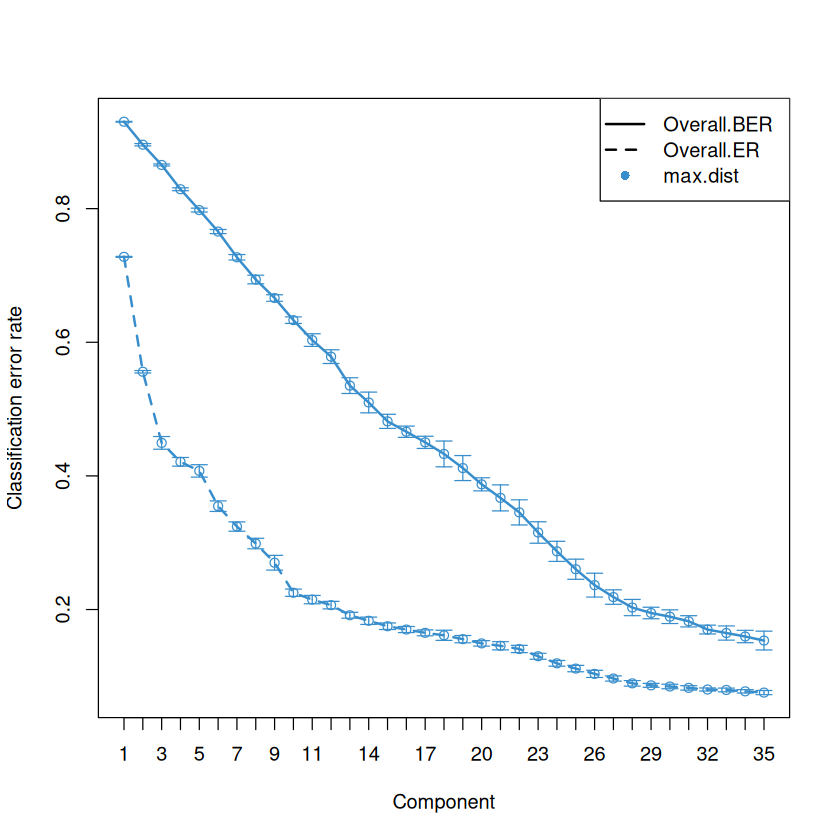

In [40]:
# ============================================================
# DIABLO
# ============================================================
design       <- matrix(0.1, nrow = 2, ncol = 2,
                       dimnames = list(c("GEX","DNAm"), c("GEX","DNAm")))
diag(design) <- 0

blocks_train <- list(GEX = X_gex_train, DNAm = X_dnam_train)

diablo_prelim <- block.splsda(X      = blocks_train,
                               Y      = Y_train,
                               ncomp  = MAX_NCOMP,
                               keepX  = list(GEX  = rep(KEEP_X, MAX_NCOMP),
                                             DNAm = rep(KEEP_X, MAX_NCOMP)),
                               design = design)
diablo_perf   <- perf(diablo_prelim,
                      validation  = "Mfold",
                      folds       = FOLDS,
                      nrepeat     = NREPEAT,
                      dist        = DIST,
                      BPPARAM     = bpparam,
                      progressBar = FALSE)
plot(diablo_perf, criterion = "BER")
saveRDS(diablo_perf, file.path(OUTPUT_DIR, "diablo_perf.rds"))

In [41]:
# ============================================================
# Extract optimal ncomp for each
# ============================================================
ncomp_gex    <- gex_perf$choice.ncomp["BER", "max.dist"]
ncomp_dnam   <- dnam_perf$choice.ncomp["BER", "max.dist"]
ncomp_diablo <- diablo_perf$choice.ncomp$WeightedVote["Overall.BER", 1]

cat("Optimal ncomp — GEX:", ncomp_gex,
    " DNAm:", ncomp_dnam,
    " DIABLO:", ncomp_diablo, "\n")

Optimal ncomp — GEX: 35  DNAm: 34  DIABLO: 34 


In [42]:
# GEX
cat("=== GEX BER per component ===\n")
print(round(gex_perf$error.rate$BER[, "max.dist"], 3))

# DNAm
cat("\n=== DNAm BER per component ===\n")
print(round(dnam_perf$error.rate$BER[, "max.dist"], 3))

# DIABLO
cat("\n=== DIABLO BER per component ===\n")
diablo_ber <- colMeans(diablo_perf$WeightedVote.error.rate$max.dist)
print(round(diablo_ber, 3))

=== GEX BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.925  0.893  0.864  0.828  0.798  0.764  0.723  0.682  0.652  0.619  0.595 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.571  0.539  0.505  0.466  0.435  0.402  0.389  0.379  0.368  0.352  0.339 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.329  0.318  0.300  0.283  0.270  0.252  0.247  0.239  0.234  0.224  0.226 
comp34 comp35 
 0.228  0.222 

=== DNAm BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.930  0.897  0.870  0.837  0.802  0.770  0.737  0.704  0.686  0.657  0.621 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.605  0.578  0.557  0.535  0.512  0.493  0.465  0.438  0.419  0.390  0.363 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.340  0.324  0.303  0.288  0.273  0.242  0.236  

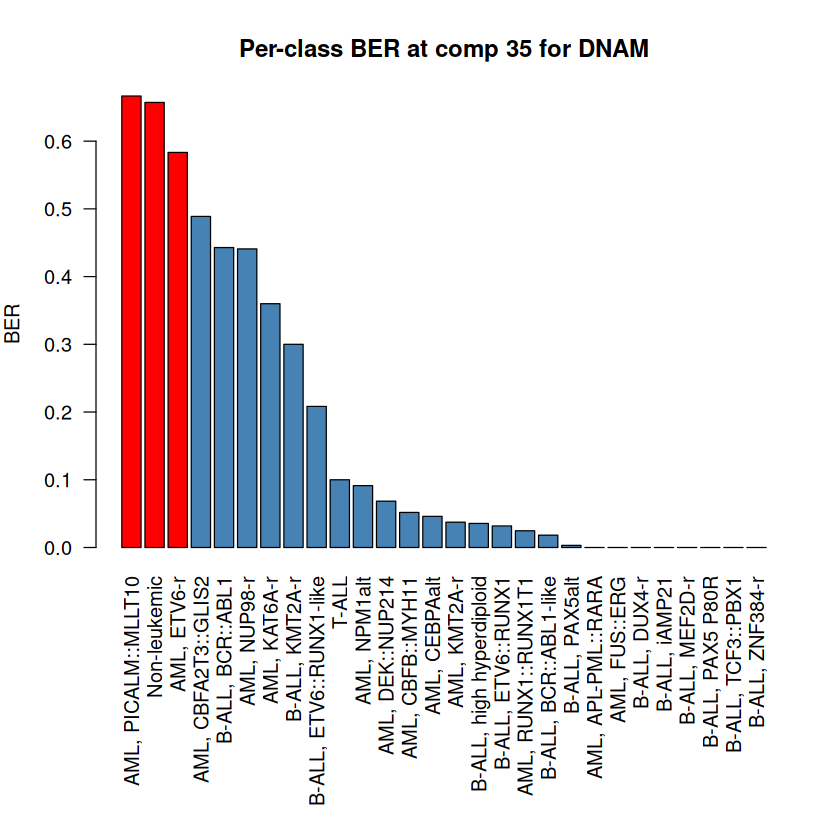

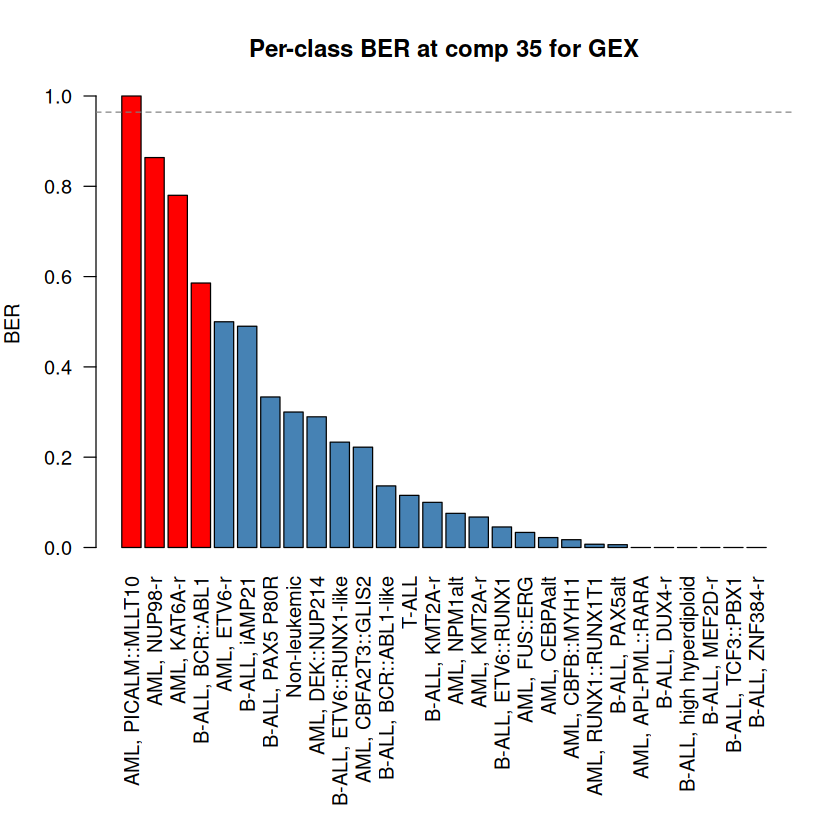

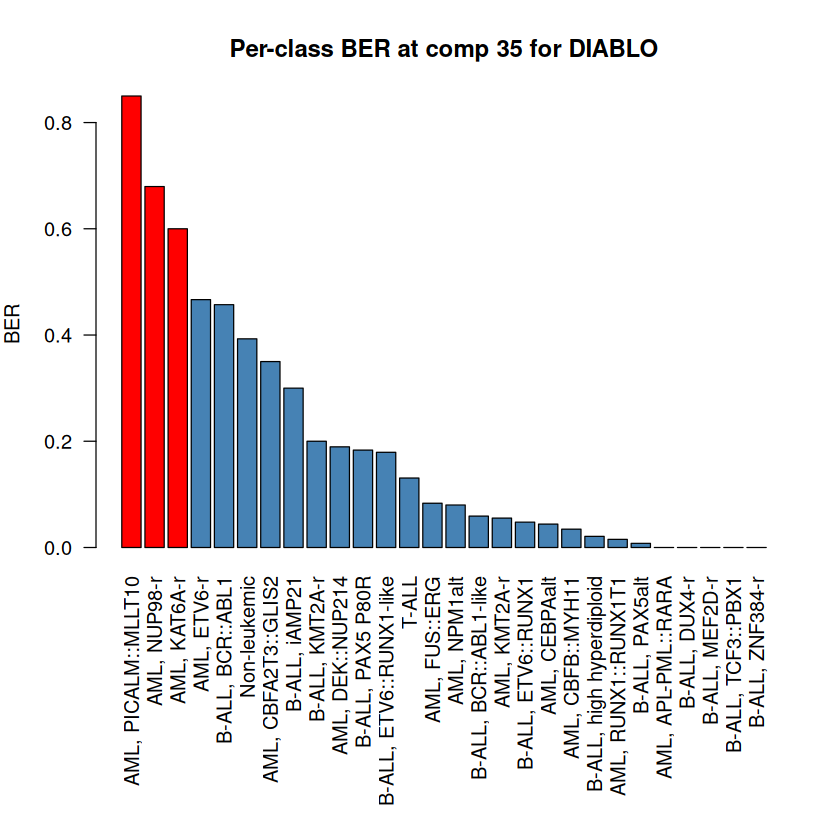

In [43]:
comp_num <- 35

dnam_ber   <- dnam_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
gex_ber    <- gex_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
diablo_ber <- rowMeans(cbind(
  diablo_perf$error.rate.per.class$GEX$max.dist[, paste0("comp", comp_num)],
  diablo_perf$error.rate.per.class$DNAm$max.dist[, paste0("comp", comp_num)]
))

plot_per_class_ber <- function(ber, comp_num, model_name) {
  ber_sorted <- sort(ber, decreasing = TRUE)
  par(mar = c(12, 4, 4, 2))  # bottom, left, top, right
  barplot(
    ber_sorted,
    las = 2,
    ylab = "BER",
    main = paste("Per-class BER at comp", comp_num, "for", model_name),
    col = ifelse(ber_sorted > 0.5, "red", "steelblue")
  )
  abline(h = 1 - 1/nlevels(Y_train), lty = 2, col = "grey50")
}

# Sort and view
plot_per_class_ber(dnam_ber, comp_num, "DNAM")
plot_per_class_ber(gex_ber, comp_num, "GEX")
plot_per_class_ber(diablo_ber, comp_num, "DIABLO")
